<a href="https://www.kaggle.com/code/hamzachaabene/notebook2c7b4a0e8e?scriptVersionId=329071886" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [1]:
import pandas as pd
import numpy as np

# IEEE-CIS له ملفان
train_transaction = pd.read_csv('/kaggle/input/datasets/hamzachaabene/train-transaction-csv/train_transaction.csv')
train_identity = pd.read_csv('/kaggle/input/datasets/tiennguyen143/train-identity-csv/train_identity.csv')

# دمجهما
df = train_transaction.merge(
    train_identity,
    on='TransactionID',
    how='left'
)

print(df.shape)        # (590540, 434)
print(df.isnull().sum().sort_values(ascending=False))

(590540, 434)
id_24            585793
id_25            585408
id_07            585385
id_08            585385
id_21            585381
                  ...  
C11                   0
C14                   0
C13                   0
C12                   0
TransactionID         0
Length: 434, dtype: int64


In [2]:
# ===== تحليل مجموعات الـ Features =====

# 1. مجموعة C (C1-C14) - عدادات
C_cols = [f'C{i}' for i in range(1, 15)]

# 2. مجموعة D (D1-D15) - فترات زمنية
D_cols = [f'D{i}' for i in range(1, 16)
          if f'D{i}' in df.columns]

# 3. مجموعة M (M1-M9) - تطابقات
M_cols = [f'M{i}' for i in range(1, 10)
          if f'M{i}' in df.columns]

# 4. مجموعة V (V1-V339) - Vesta features
V_cols = [c for c in df.columns
          if c.startswith('V')]

print("="*50)
print(f"مجموعة C: {len(C_cols)} feature")
print(f"مجموعة D: {len(D_cols)} feature")
print(f"مجموعة M: {len(M_cols)} feature")
print(f"مجموعة V: {len(V_cols)} feature")
print("="*50)

# نسبة الاحتيال في كل مجموعة
for col in C_cols[:5]:
    fraud_rate = df.groupby(
        pd.cut(df[col], bins=5)
    )['isFraud'].mean()
    print(f"\n{col} vs Fraude:")
    print(fraud_rate)

مجموعة C: 14 feature
مجموعة D: 15 feature
مجموعة M: 9 feature
مجموعة V: 339 feature

C1 vs Fraude:
C1
(-4.685, 937.0]     0.034794
(937.0, 1874.0]     0.094025
(1874.0, 2811.0]    0.200000
(2811.0, 3748.0]    0.091241
(3748.0, 4685.0]    0.133621
Name: isFraud, dtype: float64

C2 vs Fraude:
C2
(-5.691, 1138.2]    0.034775
(1138.2, 2276.4]    0.094658
(2276.4, 3414.6]    0.175141
(3414.6, 4552.8]    0.100865
(4552.8, 5691.0]    0.132075
Name: isFraud, dtype: float64

C3 vs Fraude:
C3
(-0.026, 5.2]    0.034993
(5.2, 10.4]      0.000000
(10.4, 15.6]     0.000000
(15.6, 20.8]     0.000000
(20.8, 26.0]     0.000000
Name: isFraud, dtype: float64

C4 vs Fraude:
C4
(-2.253, 450.6]     0.034783
(450.6, 901.2]      0.061576
(901.2, 1351.8]     0.144621
(1351.8, 1802.4]    0.082677
(1802.4, 2253.0]    0.138889
Name: isFraud, dtype: float64

C5 vs Fraude:
C5
(-0.349, 69.8]    0.035958
(69.8, 139.6]     0.008414
(139.6, 209.4]    0.006538
(209.4, 279.2]    0.015126
(279.2, 349.0]    0.008333
Name: 

/tmp/ipykernel_16/2395312990.py:27: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  fraud_rate = df.groupby(


أعمدة رقمية: 403


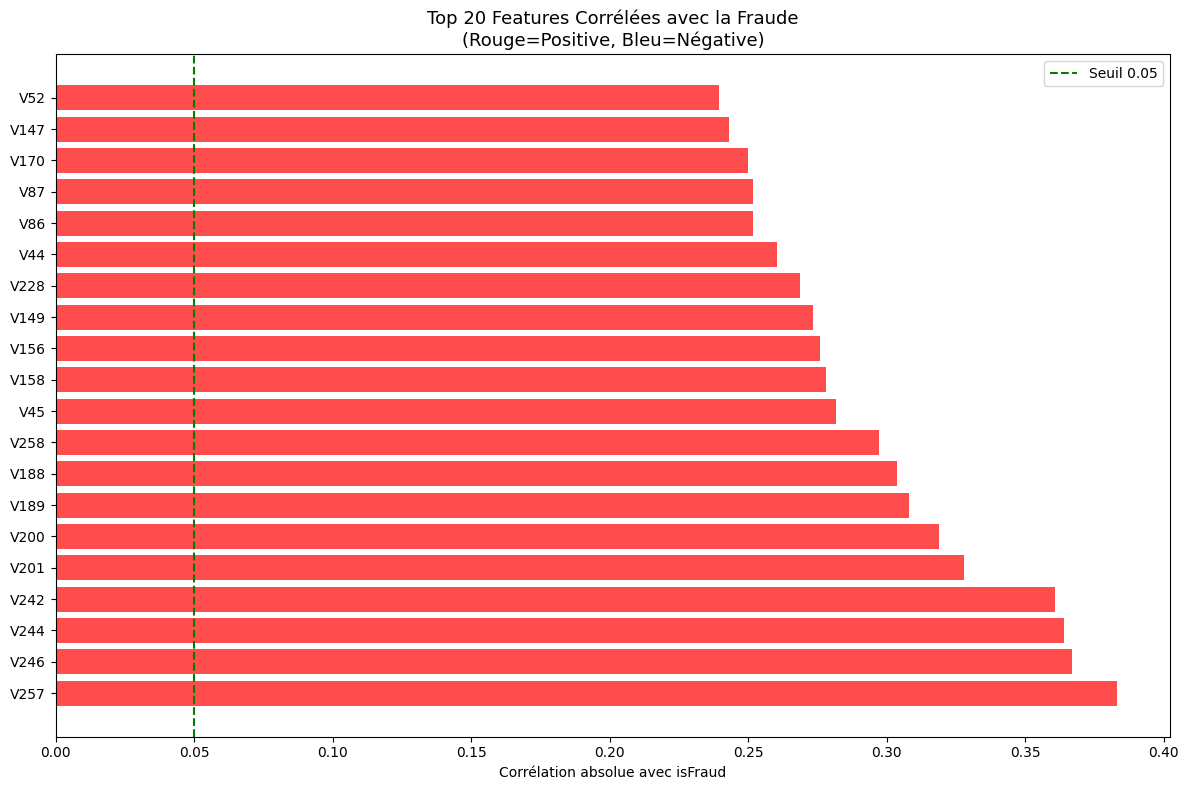


Top 20 Features les plus importantes:
↑ V257                : 0.3831
↑ V246                : 0.3669
↑ V244                : 0.3641
↑ V242                : 0.3606
↑ V201                : 0.3280
↑ V200                : 0.3188
↑ V189                : 0.3082
↑ V188                : 0.3036
↑ V258                : 0.2972
↑ V45                 : 0.2818
↑ V158                : 0.2781
↑ V156                : 0.2760
↑ V149                : 0.2733
↑ V228                : 0.2689
↑ V44                 : 0.2604
↑ V86                 : 0.2518
↑ V87                 : 0.2517
↑ V170                : 0.2498
↑ V147                : 0.2429
↑ V52                 : 0.2395

جاري رسم Heatmap لمجموعة C...


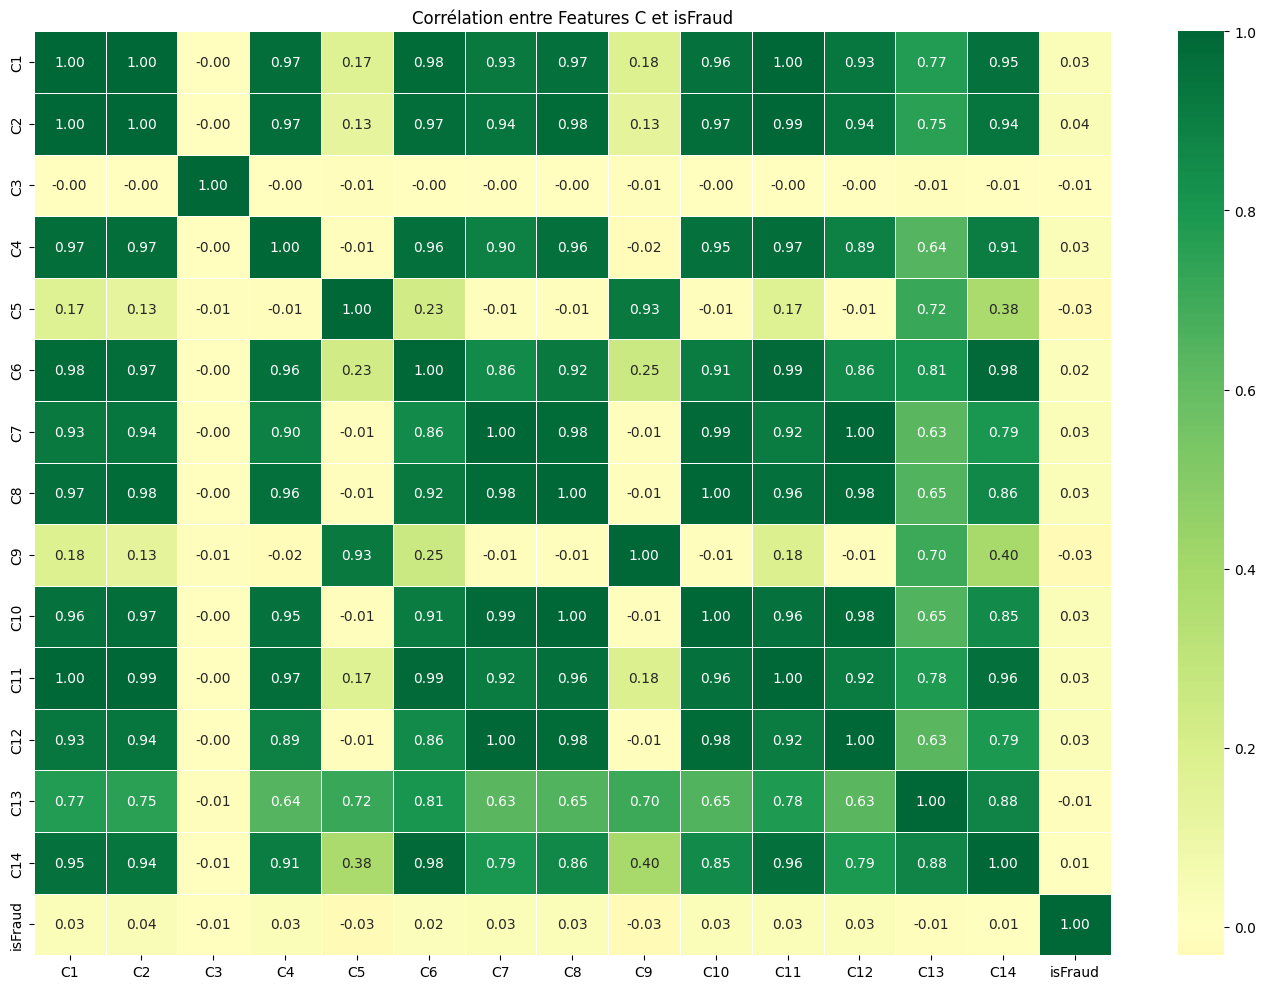

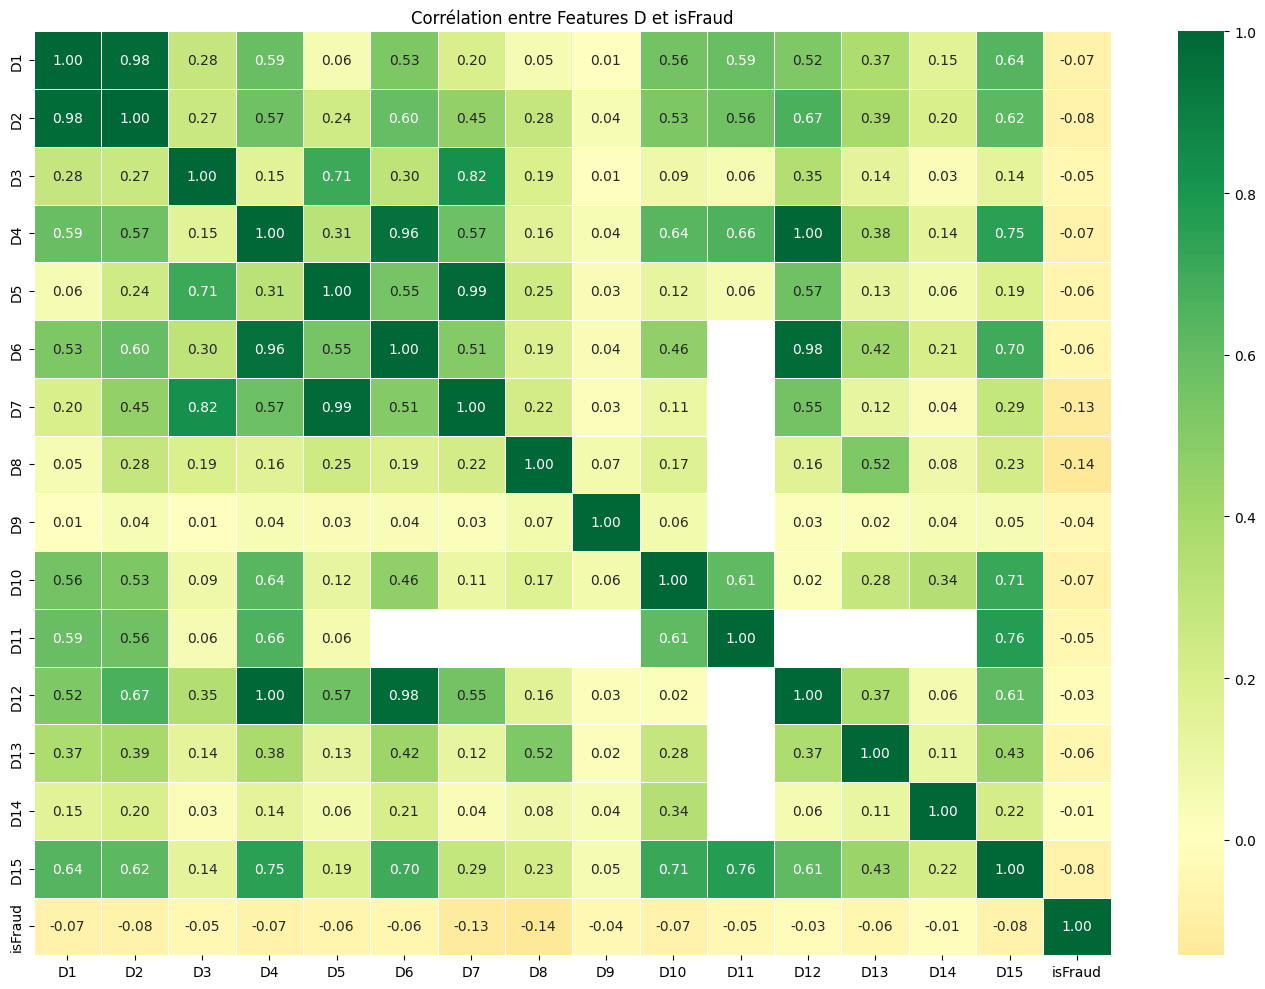

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ===== 1. أخذ الأعمدة الرقمية فقط =====
numeric_df = df.select_dtypes(
    include=['float64', 'int64']
)

print(f"أعمدة رقمية: {numeric_df.shape[1]}")

# ===== 2. Correlation مع isFraud =====
correlations = numeric_df.corr()['isFraud'].abs()
correlations = correlations.sort_values(
    ascending=False
).drop('isFraud')

# أهم 20 feature
top_20 = correlations.head(20)

# ===== 3. رسم Top 20 =====
plt.figure(figsize=(12, 8))

# لون حسب إيجابي أو سلبي
orig_corr = numeric_df.corr()['isFraud'][top_20.index]
colors = ['red' if x > 0 else 'blue'
          for x in orig_corr]

bars = plt.barh(
    range(len(top_20)),
    top_20.values,
    color=colors,
    alpha=0.7
)

plt.yticks(range(len(top_20)), top_20.index)
plt.xlabel('Corrélation absolue avec isFraud')
plt.title(
    'Top 20 Features Corrélées avec la Fraude\n'
    '(Rouge=Positive, Bleu=Négative)',
    fontsize=13
)
plt.axvline(x=0.05, color='green',
            linestyle='--', label='Seuil 0.05')
plt.legend()
plt.tight_layout()
plt.show()

# ===== 4. طباعة النتائج =====
print("\n" + "="*50)
print("Top 20 Features les plus importantes:")
print("="*50)
for feat, corr in top_20.items():
    direction = "↑" if numeric_df.corr(
    )['isFraud'][feat] > 0 else "↓"
    print(f"{direction} {feat:20}: {corr:.4f}")

# ===== 5. Heatmap لمجموعة C =====
print("\nجاري رسم Heatmap لمجموعة C...")
C_cols = [f'C{i}' for i in range(1, 15)
          if f'C{i}' in df.columns]
C_cols_with_target = C_cols + ['isFraud']

plt.figure(figsize=(14, 10))
sns.heatmap(
    df[C_cols_with_target].corr(),
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5
)
plt.title('Corrélation entre Features C et isFraud')
plt.tight_layout()
plt.show()

# ===== 6. Heatmap لمجموعة D =====
D_cols = [f'D{i}' for i in range(1, 16)
          if f'D{i}' in df.columns]
D_cols_with_target = D_cols + ['isFraud']

plt.figure(figsize=(14, 10))
sns.heatmap(
    df[D_cols_with_target].corr(),
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5
)
plt.title('Corrélation entre Features D et isFraud')
plt.tight_layout()
plt.show()

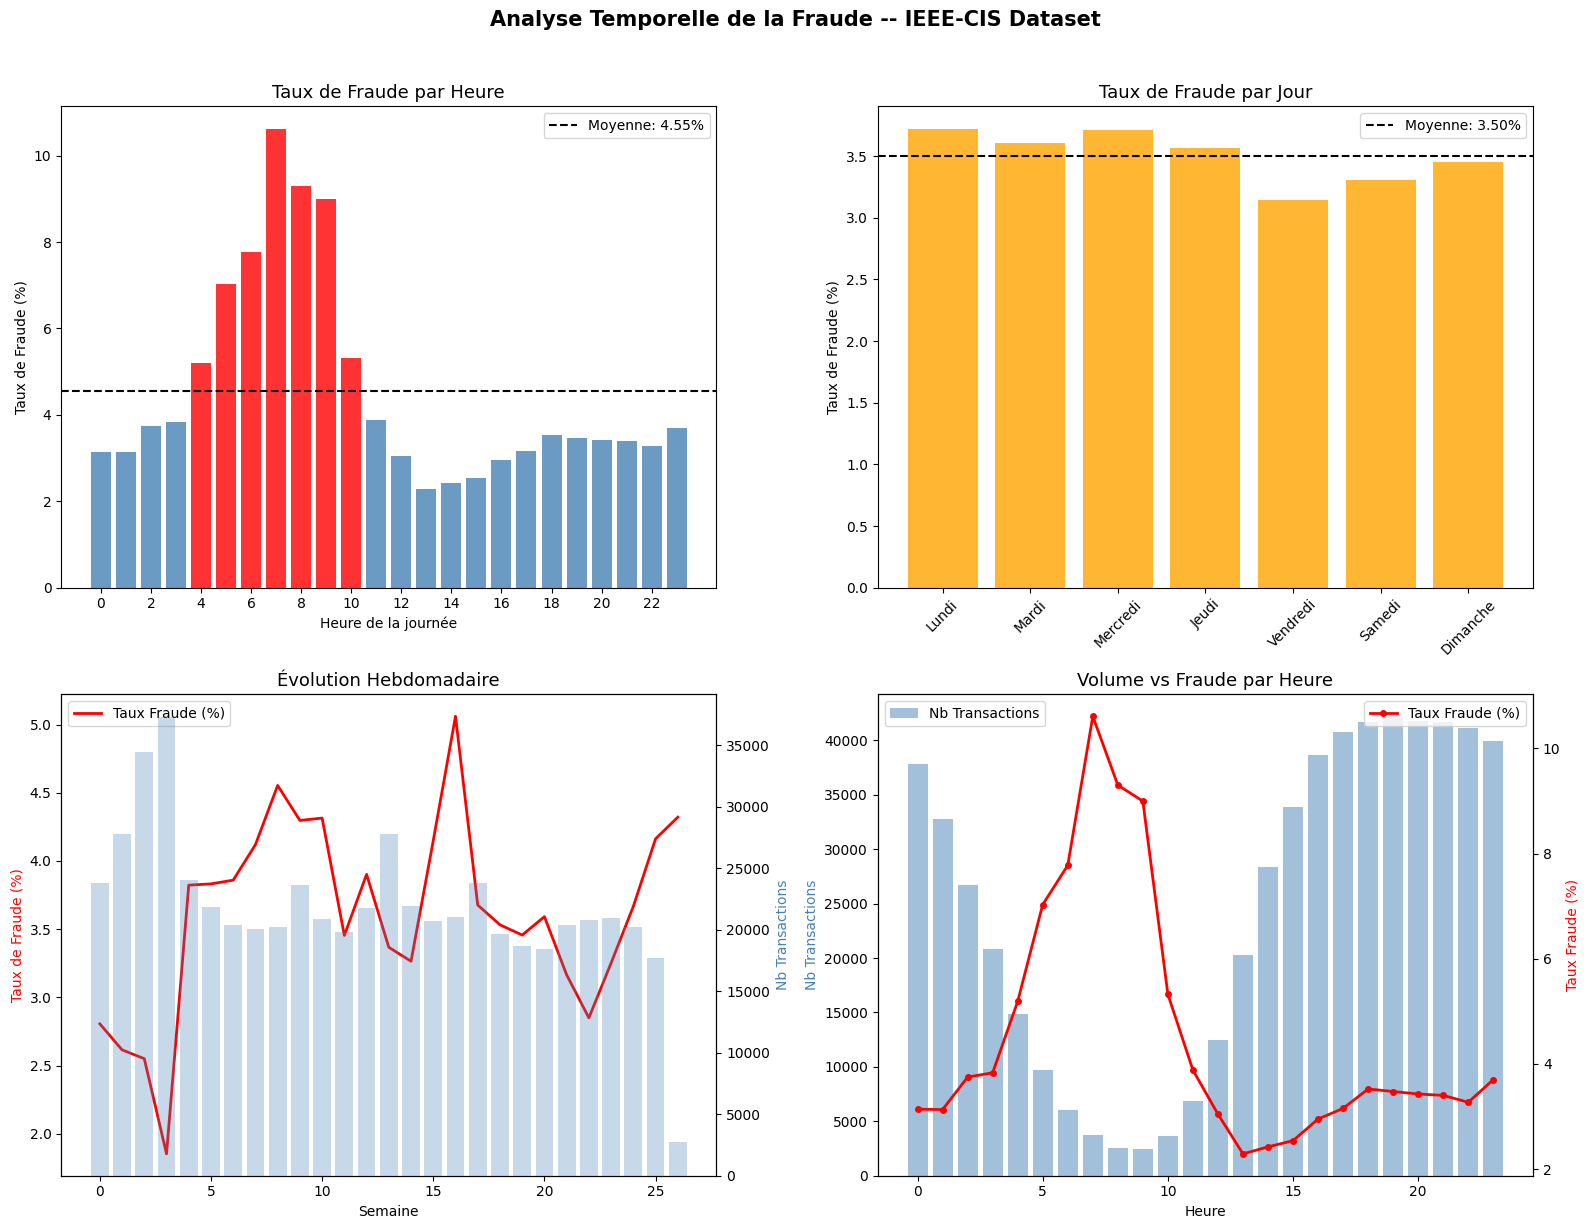

إحصاءات زمنية:

أخطر ساعة: 7h (10.61%)
أأمن ساعة:  13h (2.29%)

أخطر يوم: Lundi (3.72%)
أأمن يوم:  Vendredi (3.15%)


In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# ===== 1. احتيال حسب الساعة =====
df['hour'] = df['TransactionDT'] % 86400 // 3600

hour_stats = df.groupby('hour')['isFraud'].agg(
    ['mean', 'count', 'sum']
).reset_index()

ax1 = axes[0, 0]
bars = ax1.bar(
    hour_stats['hour'],
    hour_stats['mean'] * 100,
    color=['red' if x > hour_stats['mean'].mean()*100
           else 'steelblue'
           for x in hour_stats['mean']*100],
    alpha=0.8
)
ax1.axhline(
    y=hour_stats['mean'].mean()*100,
    color='black', linestyle='--',
    label=f"Moyenne: {hour_stats['mean'].mean()*100:.2f}%"
)
ax1.set_title('Taux de Fraude par Heure', fontsize=13)
ax1.set_xlabel('Heure de la journée')
ax1.set_ylabel('Taux de Fraude (%)')
ax1.legend()
ax1.set_xticks(range(0, 24, 2))

# ===== 2. احتيال حسب اليوم =====
df['day'] = df['TransactionDT'] // 86400 % 7

day_stats = df.groupby('day')['isFraud'].agg(
    ['mean', 'count']
).reset_index()

days = ['Lundi', 'Mardi', 'Mercredi',
        'Jeudi', 'Vendredi', 'Samedi', 'Dimanche']

ax2 = axes[0, 1]
ax2.bar(
    days[:len(day_stats)],
    day_stats['mean'] * 100,
    color='orange', alpha=0.8
)
ax2.axhline(
    y=day_stats['mean'].mean()*100,
    color='black', linestyle='--',
    label=f"Moyenne: {day_stats['mean'].mean()*100:.2f}%"
)
ax2.set_title('Taux de Fraude par Jour', fontsize=13)
ax2.set_ylabel('Taux de Fraude (%)')
ax2.legend()
plt.setp(ax2.xaxis.get_majorticklabels(), rotation=45)

# ===== 3. تطور الاحتيال أسبوعياً =====
df['week'] = df['TransactionDT'] // 86400 // 7

week_stats = df.groupby('week')['isFraud'].agg(
    ['mean', 'count', 'sum']
).reset_index()

ax3 = axes[1, 0]
ax3_twin = ax3.twinx()

ax3.plot(
    week_stats['week'],
    week_stats['mean'] * 100,
    color='red', linewidth=2,
    label='Taux Fraude (%)'
)
ax3_twin.bar(
    week_stats['week'],
    week_stats['count'],
    color='steelblue', alpha=0.3,
    label='Nb Transactions'
)
ax3.set_title('Évolution Hebdomadaire', fontsize=13)
ax3.set_xlabel('Semaine')
ax3.set_ylabel('Taux de Fraude (%)', color='red')
ax3_twin.set_ylabel('Nb Transactions', color='steelblue')
ax3.legend(loc='upper left')

# ===== 4. Volume vs Fraude par heure =====
ax4 = axes[1, 1]
ax4_twin = ax4.twinx()

ax4.bar(
    hour_stats['hour'],
    hour_stats['count'],
    color='steelblue', alpha=0.5,
    label='Nb Transactions'
)
ax4_twin.plot(
    hour_stats['hour'],
    hour_stats['mean'] * 100,
    color='red', linewidth=2,
    marker='o', markersize=4,
    label='Taux Fraude (%)'
)
ax4.set_title('Volume vs Fraude par Heure', fontsize=13)
ax4.set_xlabel('Heure')
ax4.set_ylabel('Nb Transactions', color='steelblue')
ax4_twin.set_ylabel('Taux Fraude (%)', color='red')
ax4.legend(loc='upper left')
ax4_twin.legend(loc='upper right')

plt.suptitle(
    'Analyse Temporelle de la Fraude -- IEEE-CIS Dataset',
    fontsize=15, fontweight='bold', y=1.02
)
plt.tight_layout()
plt.show()

# ===== طباعة الإحصاءات =====
print("="*50)
print("إحصاءات زمنية:")
print("="*50)
print(f"\nأخطر ساعة: {hour_stats.loc[hour_stats['mean'].idxmax(), 'hour']}h "
      f"({hour_stats['mean'].max()*100:.2f}%)")
print(f"أأمن ساعة:  {hour_stats.loc[hour_stats['mean'].idxmin(), 'hour']}h "
      f"({hour_stats['mean'].min()*100:.2f}%)")
print(f"\nأخطر يوم: {days[day_stats['mean'].idxmax()]} "
      f"({day_stats['mean'].max()*100:.2f}%)")
print(f"أأمن يوم:  {days[day_stats['mean'].idxmin()]} "
      f"({day_stats['mean'].min()*100:.2f}%)")

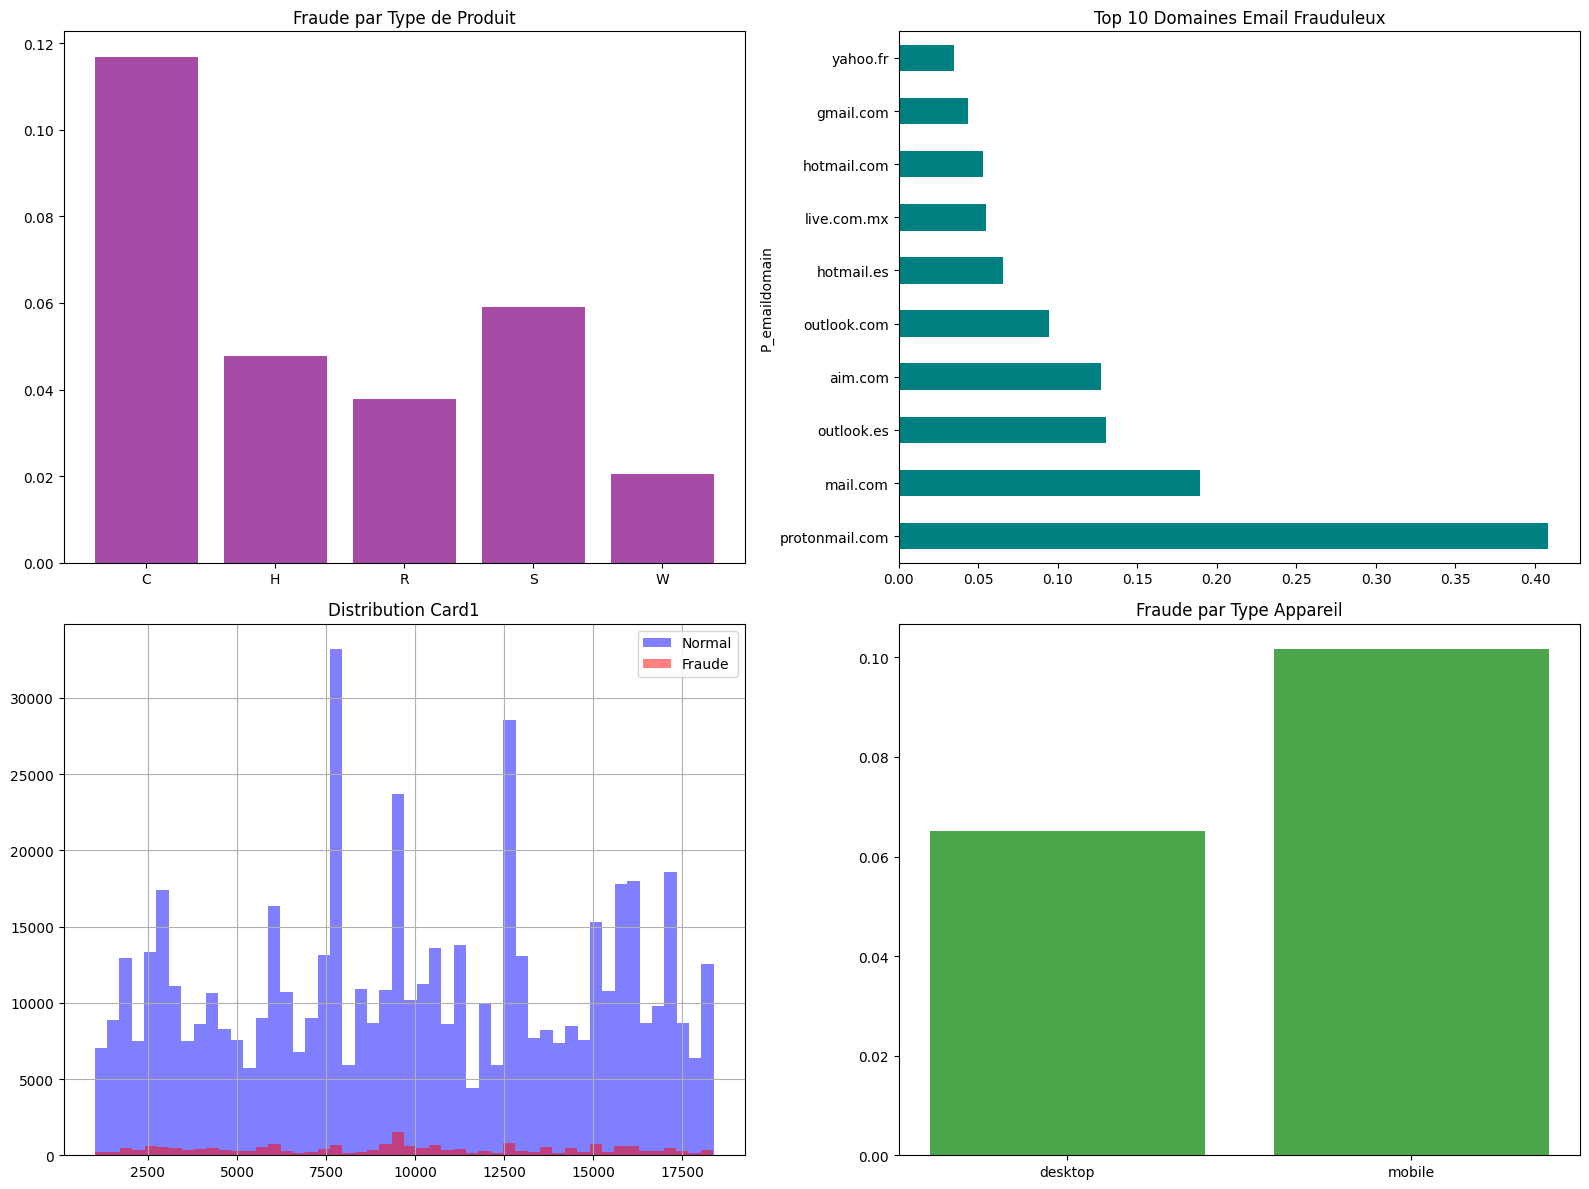

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. احتيال حسب نوع المنتج
product_fraud = df.groupby('ProductCD')['isFraud'].mean()
axes[0,0].bar(
    product_fraud.index,
    product_fraud.values,
    color='purple', alpha=0.7
)
axes[0,0].set_title('Fraude par Type de Produit')

# 2. احتيال حسب domain email
email_fraud = df.groupby(
    'P_emaildomain'
)['isFraud'].mean().sort_values(
    ascending=False
).head(10)

email_fraud.plot(
    kind='barh',
    ax=axes[0,1],
    color='teal'
)
axes[0,1].set_title('Top 10 Domaines Email Frauduleux')

# 3. توزيع card1 (log scale)
df[df['isFraud']==0]['card1'].hist(
    bins=50, color='blue',
    alpha=0.5, label='Normal',
    ax=axes[1,0]
)
df[df['isFraud']==1]['card1'].hist(
    bins=50, color='red',
    alpha=0.5, label='Fraude',
    ax=axes[1,0]
)
axes[1,0].set_title('Distribution Card1')
axes[1,0].legend()

# 4. DeviceType vs Fraude
if 'DeviceType' in df.columns:
    device_fraud = df.groupby(
        'DeviceType'
    )['isFraud'].mean()
    axes[1,1].bar(
        device_fraud.index,
        device_fraud.values,
        color='green', alpha=0.7
    )
    axes[1,1].set_title('Fraude par Type Appareil')

plt.tight_layout()
plt.show()

In [6]:
# ===== 1. تصنيف الأعمدة =====
# أعمدة بأكثر من 90% فارغة → نحذفها
cols_to_drop = df.columns[
    df.isnull().mean() > 0.9
].tolist()

print(f"أعمدة سنحذفها: {len(cols_to_drop)}")
print(cols_to_drop)

df = df.drop(columns=cols_to_drop)
print(f"\nالشكل بعد الحذف: {df.shape}")

# ===== 2. تصنيف باقي الأعمدة =====
num_cols = df.select_dtypes(
    include=['float64', 'int64']
).columns.tolist()

cat_cols = df.select_dtypes(
    include=['object']
).columns.tolist()

# إزالة الهدف من القوائم
num_cols = [c for c in num_cols if c != 'isFraud']
num_cols = [c for c in num_cols if c != 'TransactionID']

print(f"\nأعمدة رقمية:  {len(num_cols)}")
print(f"أعمدة نصية:   {len(cat_cols)}")

# ===== 3. ملء القيم الفارغة =====
# الأعمدة الرقمية ← بالوسيط
for col in num_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].median())

# الأعمدة النصية ← بـ "Unknown"
for col in cat_cols:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna("Unknown")

# ===== 4. التحقق =====
print("\n" + "="*50)
print("بعد المعالجة:")
print("="*50)
print(f"القيم الفارغة المتبقية: {df.isnull().sum().sum()}")
print(f"الشكل النهائي: {df.shape}")

أعمدة سنحذفها: 12
['dist2', 'D7', 'id_07', 'id_08', 'id_18', 'id_21', 'id_22', 'id_23', 'id_24', 'id_25', 'id_26', 'id_27']

الشكل بعد الحذف: (590540, 425)

أعمدة رقمية:  394
أعمدة نصية:   29

بعد المعالجة:
القيم الفارغة المتبقية: 0
الشكل النهائي: (590540, 425)


Features الجديدة:
✅ Transaction_hour: int64
✅ Transaction_day: int64
✅ Transaction_week: int64
✅ Amt_vs_card1_mean: float64
✅ Amt_is_round: int64
✅ Amt_log: float64
✅ card1_count: int64
✅ card2_count: int64
✅ addr1_count: int64

الشكل الجديد: (590540, 434)


/tmp/ipykernel_16/963147216.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Transaction_hour'] = df['TransactionDT'] % 86400 // 3600
/tmp/ipykernel_16/963147216.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df['Transaction_day']  = df['TransactionDT'] // 86400 % 7
/tmp/ipykernel_16/963147216.py:4: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To g

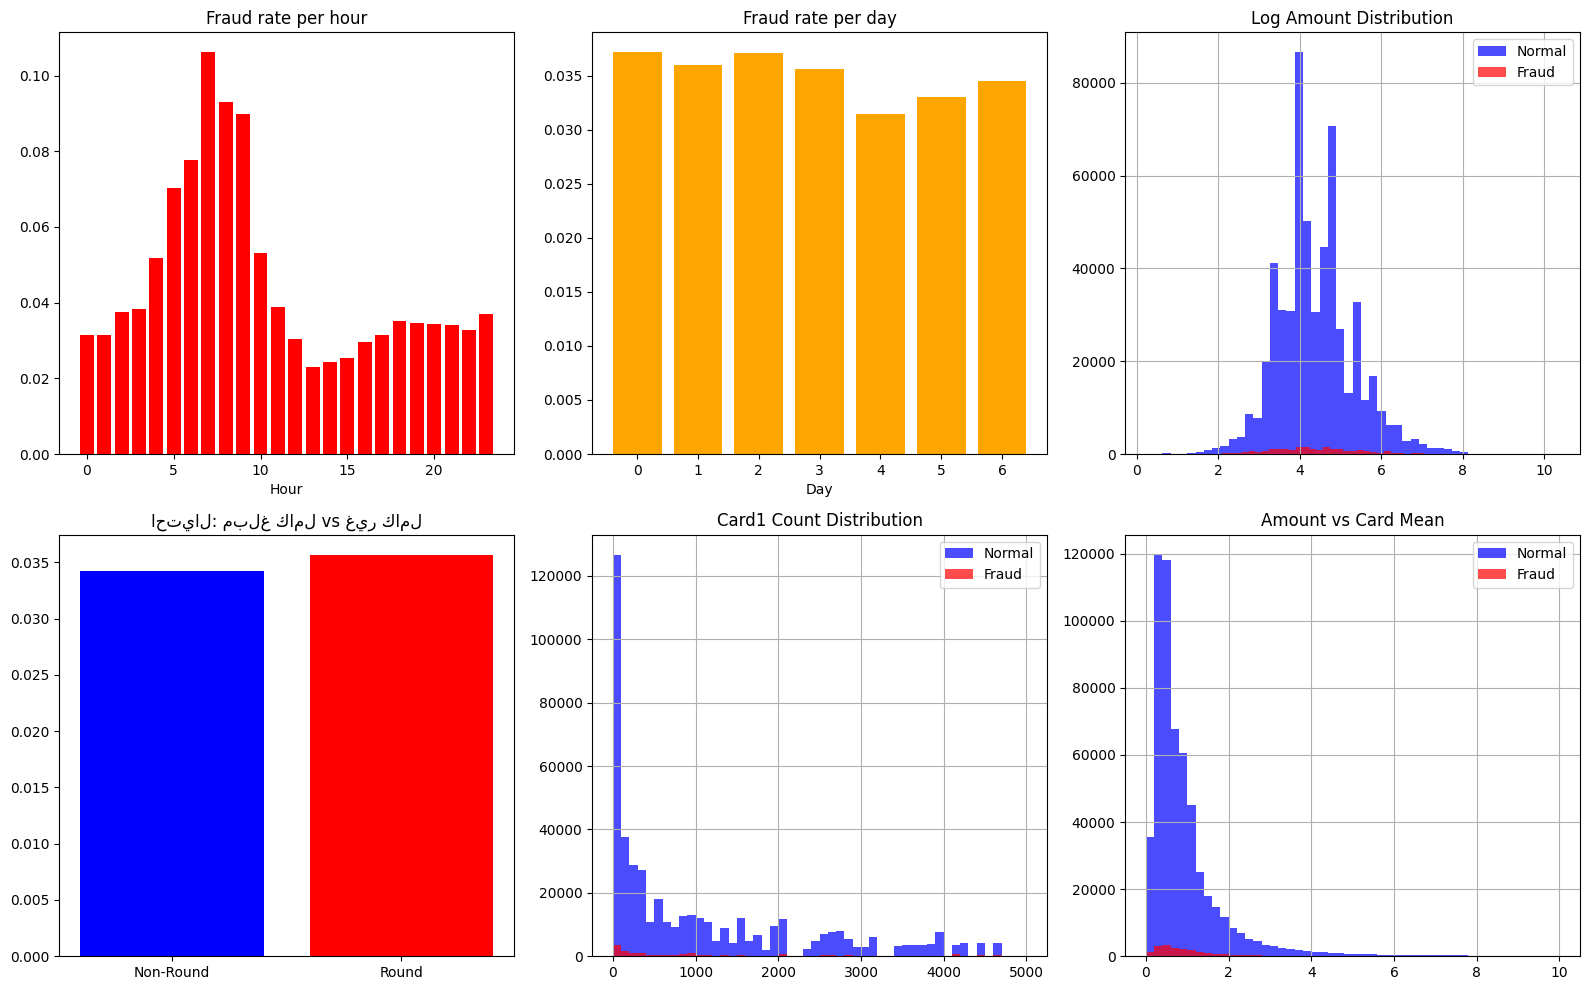

In [7]:
# ===== 1. Features زمنية =====
df['Transaction_hour'] = df['TransactionDT'] % 86400 // 3600
df['Transaction_day']  = df['TransactionDT'] // 86400 % 7
df['Transaction_week'] = df['TransactionDT'] // 86400 // 7

# ===== 2. Features من المبلغ =====
# نسبة المبلغ لمتوسط البطاقة
df['Amt_vs_card1_mean'] = (
    df['TransactionAmt'] /
    df.groupby('card1')['TransactionAmt'].transform('mean')
)

# هل المبلغ رقم كامل؟
df['Amt_is_round'] = (
    df['TransactionAmt'] % 1 == 0
).astype(int)

# logarithme المبلغ
df['Amt_log'] = np.log1p(df['TransactionAmt'])

# ===== 3. Features من تكرار البطاقة =====
df['card1_count'] = df.groupby('card1')['card1'].transform('count')
df['card2_count'] = df.groupby('card2')['card2'].transform('count')

# ===== 4. Features من العنوان =====
df['addr1_count'] = df.groupby('addr1')['addr1'].transform('count')

# ===== 5. تحقق =====
new_features = [
    'Transaction_hour', 'Transaction_day',
    'Transaction_week', 'Amt_vs_card1_mean',
    'Amt_is_round', 'Amt_log',
    'card1_count', 'card2_count', 'addr1_count'
]

print("="*50)
print("Features الجديدة:")
print("="*50)
for f in new_features:
    print(f"✅ {f}: {df[f].dtype}")

print(f"\nالشكل الجديد: {df.shape}")

# ===== 6. رسم Features الجديدة =====
fig, axes = plt.subplots(2, 3, figsize=(16, 10))

# توزيع الاحتيال حسب الساعة
fraud_by_hour = df.groupby('Transaction_hour')['isFraud'].mean()
axes[0,0].bar(fraud_by_hour.index, fraud_by_hour.values, color='red')
axes[0,0].set_title('Fraud rate per hour')
axes[0,0].set_xlabel('Hour')

# توزيع الاحتيال حسب اليوم
fraud_by_day = df.groupby('Transaction_day')['isFraud'].mean()
axes[0,1].bar(fraud_by_day.index, fraud_by_day.values, color='orange')
axes[0,1].set_title('Fraud rate per day')
axes[0,1].set_xlabel('Day')

# توزيع Log Amount
df[df['isFraud']==0]['Amt_log'].hist(
    bins=50, color='blue', alpha=0.7,
    ax=axes[0,2], label='Normal'
)
df[df['isFraud']==1]['Amt_log'].hist(
    bins=50, color='red', alpha=0.7,
    ax=axes[0,2], label='Fraud'
)
axes[0,2].set_title('Log Amount Distribution')
axes[0,2].legend()

# هل المبلغ رقم كامل؟
round_fraud = df.groupby('Amt_is_round')['isFraud'].mean()
axes[1,0].bar(['Non-Round', 'Round'],
              round_fraud.values,
              color=['blue', 'red'])
axes[1,0].set_title('احتيال: مبلغ كامل vs غير كامل')

# توزيع card1_count
df[df['isFraud']==0]['card1_count'].hist(
    bins=50, color='blue', alpha=0.7,
    ax=axes[1,1], label='Normal', range=(0,5000)
)
df[df['isFraud']==1]['card1_count'].hist(
    bins=50, color='red', alpha=0.7,
    ax=axes[1,1], label='Fraud', range=(0,5000)
)
axes[1,1].set_title('Card1 Count Distribution')
axes[1,1].legend()

# Amt_vs_card1_mean
df[df['isFraud']==0]['Amt_vs_card1_mean'].hist(
    bins=50, color='blue', alpha=0.7,
    ax=axes[1,2], label='Normal', range=(0,10)
)
df[df['isFraud']==1]['Amt_vs_card1_mean'].hist(
    bins=50, color='red', alpha=0.7,
    ax=axes[1,2], label='Fraud', range=(0,10)
)
axes[1,2].set_title('Amount vs Card Mean')
axes[1,2].legend()

plt.tight_layout()
plt.show()